In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os
import glob as glob

import sqlite3 

In [2]:
# Set data and output directories
PARENT_DIR = '/n/holylfs05/LABS/arguelles_delgado_lab/Everyone/jbook/double_cascade_identification/'
EXAMPLE_OUTPUT_DIR = PARENT_DIR + 'training_output'
data_parent_dir = '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/'
dataset_ids = ['new_190300', 'new_190312', 'new_190313', 'new_190314', 'with_cuts/oscNext']
# Include oscNext for background, exclude for signal
# Removing 190311 because it has a lot of hnl single cascade events

dataset_paths = []
for did in dataset_ids:
    dataset_paths.extend(glob.glob(os.path.join(data_parent_dir, "{}".format(did), "merged/merged.db")))
print("datasets: \n")
print(dataset_paths)

datasets: 

['/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190300/merged/merged.db', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190312/merged/merged.db', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190313/merged/merged.db', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190314/merged/merged.db', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/with_cuts/oscNext/merged/merged.db']


In [3]:
data_parent_dir = '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/'
dataset_ids = ['new_190311', 'new_190312', 'new_190313', 'new_190314']

background_parent_dir = '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite2/'
background_ids =  ['oscNext']

dataset_paths = []
for did in dataset_ids:
    dataset_paths.extend(glob.glob(os.path.join(data_parent_dir, "{}".format(did), "merged/merged.db")))

background_paths = []
for did in background_ids:
    background_paths.extend(glob.glob(os.path.join(background_parent_dir, "{}".format(did), "merged/merged.db")))
 

In [4]:
print(dataset_paths)

['/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190311/merged/merged.db', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190312/merged/merged.db', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190313/merged/merged.db', '/n/holylfs05/LABS/arguelles_delgado_lab/Lab/IceCube_MC/HNL/sqlite_L3/new_190314/merged/merged.db']


In [3]:
# create connection to the database 
connection = sqlite3.connect(dataset_paths[0]) 
# background_conn = sqlite3.connect(background_paths[0])
# query to display all data in the table 
# cursor = connection.execute("SELECT * from truth") 

sql_query="SELECT * from truth"

db = pd.read_sql(sql_query, connection)
db.head()

,energy,position_x,position_y,position_z,azimuth,zenith,pid,event_time,sim_type,interaction_type,...,CascadeFilter_13,MuonFilter_13,OnlineL2Filter_17,L3_oscNext_bool,L4_oscNext_bool,L5_oscNext_bool,L6_oscNext_bool,L7_oscNext_bool,event_weight,event_no
0,574.419769,55.709437,-166.725865,-411.200237,1.518917,1.705586,16.0,1.087909e+17,NuGen,-1.0,...,1.0,0.0,0.0,0.0,-1.0,-1.0,-1.0,-1.0,1.006476e-16,0
1,208.009460,20.371044,-98.520510,-240.996397,0.214054,2.139593,16.0,1.087909e+17,NuGen,-1.0,...,1.0,1.0,0.0,1.0,-1.0,-1.0,-1.0,-1.0,1.555848e-15,1
2,370.550268,42.862713,132.352599,-476.602679,0.964709,2.536756,16.0,1.087909e+17,NuGen,-1.0,...,1.0,0.0,0.0,1.0,-1.0,-1.0,-1.0,-1.0,7.446711e-18,2
3,98.653192,-129.786154,122.314570,-406.427380,4.772617,2.895438,16.0,1.087909e+17,NuGen,-1.0,...,0.0,0.0,0.0,1.0,-1.0,-1.0,-1.0,-1.0,1.281942e-15,3
4,3414.195304,260.507865,-115.230515,-145.066276,3.490080,1.891042,16.0,1.087909e+17,NuGen,-1.0,...,1.0,1.0,1.0,0.0,-1.0,-1.0,-1.0,-1.0,7.355067e-21,4


In [6]:

sql_query="SELECT * from SRTInIcePulses"

db = pd.read_sql(sql_query, connection)
db.head()
connection.close()

In [7]:
db.keys()

Index(['charge', 'dom_time', 'width', 'dom_x', 'dom_y', 'dom_z', 'pmt_area',
       'rde', 'is_bright_dom', 'is_bad_dom', 'is_saturated_dom',
       'is_errata_dom', 'event_time', 'hlc', 'awtd', 'string', 'pmt_number',
       'dom_number', 'dom_type', 'event_no'],
      dtype='object')

In [ ]:
# create connection to the database 
connection = sqlite3.connect(background_paths[0]) 

sql_query="SELECT * from SRTInIcePulses"

back_db = pd.read_sql(sql_query, connection)
back_db.head()
connection.close()

In [ ]:
plt.hist(db["dom_number"], histtype="step", label="hnl")
plt.hist(back_db["dom_number"], histtype="step", label="neutrino background")

In [9]:
db['DeepCoreFilter_13']

0       1.0
1       1.0
2       1.0
3       1.0
4       1.0
       ... 
2076    1.0
2077    1.0
2078    1.0
2079    1.0
2080    1.0
Name: DeepCoreFilter_13, Length: 2081, dtype: float64

Text(0.5, 1.0, 'events passing deepcore_13 cut')

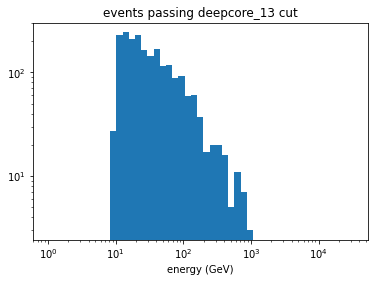

In [8]:
binning = np.logspace(0, 4.5, 50)
plt.hist(db['energy'], bins=binning)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('energy (GeV)')
plt.title('events passing deepcore_13 cut')

In [5]:
### Add an is_hnl columns, marks true for HNL files
for file in [dataset_paths[0]]:
    # Connecting to sqlite
    connection_obj = sqlite3.connect(file)

    # cursor object
    cursor = connection_obj.cursor()

    # Add a new column to table
    try:
        new_column = "ALTER TABLE truth ADD COLUMN is_hnl BOOLEAN"
        cursor.execute(new_column)
    except:
        print("column was already there")
    finally:
        cursor.execute("UPDATE truth SET is_hnl = 1")
        connection_obj.commit()

        # Close the connection
        connection_obj.close()

In [29]:
### Add an is_hnl columns, marks false for background files
for file in background_paths:
    # Connecting to sqlite
    connection_obj = sqlite3.connect(file)

    # cursor object
    cursor = connection_obj.cursor()

    # Add a new column to table
    try:
        new_column = "ALTER TABLE truth ADD COLUMN is_hnl BOOLEAN"
        cursor.execute(new_column)
    except:
        print("column was already there")
    finally:
        cursor.execute("UPDATE truth SET is_hnl = 0")
        connection_obj.commit()

        # Close the connection
        connection_obj.close()

In [6]:
# Check changes
connection = sqlite3.connect(dataset_paths[0]) 
sql_query="SELECT * from truth"

db = pd.read_sql(sql_query, connection)
db['is_hnl'].head()

0    1
1    1
2    1
3    1
4    1
Name: is_hnl, dtype: int64